# 02 · Preprocesamiento de los datos

**Universidad de Especialidades Espíritu Santo (UEES)** · Maestría en Inteligencia Artificial
**Proyecto Integrador en Inteligencia Artificial (MIAR0545)** · Proyecto final
**Autor:** Jairo Wladimir Jhayya Perlaza · **Docente:** Gladys María Villegas Rugel · **Fecha:** octubre de 2026

**Proyecto:** Análisis comparativo de modelos de aprendizaje automático y arquitecturas Transformer para la clasificación
de tráfico de red cifrado sobre el dataset CESNET-TLS-Year22.


Este notebook explica cómo cada flujo de red se convierte en los datos que reciben los modelos: qué variables se
usan, cuáles se excluyen y por qué, cómo se tratan las variables muy asimétricas, cómo se representa la secuencia de
paquetes y cómo se dividen los datos en el tiempo.

Para que cualquiera pueda ejecutarlo sin descargar el dataset completo, el notebook trabaja con la muestra pública que
está en el repositorio (`data/samples/muestra_prueba_octubre.parquet`): 6 900 flujos de octubre, 300 de cada categoría.
Esa muestra está balanceada a propósito para la aplicación web, así que no refleja el desbalance real. Las cifras de los
datos completos (3 133 138 flujos) provienen del análisis exploratorio y se leen de `results/eda/`.

## Configuración

Se cargan las librerías y se ubica la raíz del proyecto subiendo carpetas hasta encontrar `configs/`, así el notebook
funciona sin importar desde dónde se abra. También se definen dos funciones pequeñas para leer resultados y mostrar
figuras.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

# La raíz del proyecto es la primera carpeta, subiendo desde aquí, que contiene configs/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").exists())
RES = RAIZ / "results"
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 60)


def leer_json(ruta):
    """Lee un archivo JSON de resultados."""
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def figura(ruta, ancho=900):
    """Muestra una figura guardada por los scripts del proyecto."""
    display(Image(filename=str(ruta), width=ancho))


print("Raíz del proyecto:", RAIZ.name, "· resultados disponibles:", RES.exists())

import sys

sys.path.insert(0, str(RAIZ))
from src import data_processing as dp  # el módulo de preprocesamiento del proyecto

Raíz del proyecto: pf · resultados disponibles: True


## 1. Los datos de partida

Cada fila es un flujo TLS: una conexión cifrada entre un cliente y un servidor. Del flujo solo se conocen metadatos,
nunca el contenido. La celda carga la muestra pública y agrupa sus columnas según el papel que cumplen.

In [2]:
muestra = pd.read_parquet(RAIZ / "data" / "samples" / "muestra_prueba_octubre.parquet")
secuencia = [c for c in muestra.columns if c.startswith(("SIZE_", "DIR_", "IPT_"))]
otras = [c for c in muestra.columns if c not in dp.TABULAR and c not in secuencia]

grupos = pd.DataFrame(
    [
        ("Variables tabulares (Random Forest y XGBoost)", len(dp.TABULAR)),
        ("Secuencia de paquetes (CNN y Transformer)", len(secuencia)),
        ("Otras columnas, no usadas como entrada", len(otras)),
    ],
    columns=["Grupo", "Columnas"],
)
print(f"Muestra: {len(muestra):,} flujos y {muestra.shape[1]} columnas · {muestra.CATEGORY.nunique()} categorías".replace(",", " "))
grupos

Muestra: 6 900 flujos y 185 columnas · 23 categorías


,Grupo,Columnas
0,Variables tabulares (Random Forest y XGBoost),60
1,Secuencia de paquetes (CNN y Transformer),90
2,"Otras columnas, no usadas como entrada",35


Las 60 variables tabulares se agrupan en cuatro familias: estadísticas del flujo (duración, bytes y paquetes en cada
sentido), banderas TCP, el motivo por el que terminó el flujo e histogramas de tamaños y tiempos de los paquetes. La
celda siguiente muestra cuántas hay de cada tipo.

In [3]:
familias = {
    "Estadísticas del flujo": [c for c in dp.TABULAR if not c.startswith(("FLAG_", "FLOW_ENDREASON", "PHIST_"))],
    "Banderas TCP": [c for c in dp.TABULAR if c.startswith("FLAG_")],
    "Motivo de fin del flujo": [c for c in dp.TABULAR if c.startswith("FLOW_ENDREASON")],
    "Histogramas de tamaños y tiempos": [c for c in dp.TABULAR if c.startswith("PHIST_")],
}
pd.DataFrame([(f, len(v), ", ".join(v[:4]) + (" …" if len(v) > 4 else "")) for f, v in familias.items()],
             columns=["Familia", "Variables", "Ejemplos"])

,Familia,Variables,Ejemplos
0,Estadísticas del flujo,8,"DURATION, BYTES, BYTES_REV, PACKETS …"
1,Banderas TCP,16,"FLAG_CWR, FLAG_CWR_REV, FLAG_ECE, FLAG_ECE_REV …"
2,Motivo de fin del flujo,4,"FLOW_ENDREASON_IDLE, FLOW_ENDREASON_ACTIVE, FLOW_ENDREAS..."
3,Histogramas de tamaños y tiempos,32,"PHIST_SRC_SIZES_0, PHIST_SRC_SIZES_1, PHIST_SRC_SIZES_2,..."


## 2. Qué se excluye y por qué

Tan importante como lo que se usa es lo que se deja fuera. El dataset original incluye las direcciones IP, el nombre
del servidor (SNI), la huella del cliente TLS (JA3) y el sistema autónomo de destino (ASN). Las tres primeras se
excluyeron por privacidad, porque identifican personas o servicios concretos. El ASN de destino se excluyó por otra
razón: filtraba la respuesta. El análisis exploratorio midió cuánta información comparte cada variable con la
categoría, y el ASN resultó tan revelador que un modelo podría acertar solo por saber a qué red se conecta el flujo,
sin aprender nada del comportamiento del tráfico.

In [4]:
fuga = pd.read_csv(RES / "eda" / "fuga_de_informacion.csv").rename(columns={"Unnamed: 0": "Variable"})
fuga

,Variable,valores_distintos,NMI_con_categoria,pureza_ponderada
0,DST_ASN,139.0,0.4302,0.4131
1,DST_PORT,1.0,0.0000,0.1074
2,PPI_LEN (referencia),NaN,0.0800,NaN
3,PPI_ROUNDTRIPS (referencia),NaN,0.0469,NaN


La información mutua normalizada del ASN de destino con la categoría es de 0,430, mientras que variables legítimas
como la longitud de la secuencia apenas llegan a 0,08. La celda siguiente comprueba que ninguna variable excluida se
cuele entre las entradas del modelo.

In [5]:
excluidas = {"SRC_IP", "DST_IP", "TLS_SNI", "TLS_JA3", "DST_ASN", "SRC_ASN"}
print("Variables excluidas presentes entre las entradas:", excluidas & set(dp.TABULAR) or "ninguna")
print("Columnas de la muestra que no son entradas:", ", ".join(otras[:6]), "…")

Variables excluidas presentes entre las entradas: ninguna
Columnas de la muestra que no son entradas: DATE, TIME_FIRST, APP, CATEGORY, PUSH_0, PUSH_1 …


## 3. Calidad de los datos

Antes de transformar nada, el análisis exploratorio revisó la calidad de los 3 133 138 flujos de la muestra del 2 %.
La celda resume esa revisión.

In [6]:
resumen_eda = leer_json(RES / "eda" / "resumen_eda.json")
calidad = resumen_eda["calidad"]
print(f"Completitud: {calidad['completitud_%']} %")
print(f"Duraciones negativas: {calidad['duracion_negativa']} · bytes negativos: {calidad['bytes_negativos']}")
print(f"Longitudes de secuencia fuera del rango 1 a 30: {calidad['ppi_len_fuera_de_1_30']}")

Completitud: 100.0 %
Duraciones negativas: 0 · bytes negativos: 0
Longitudes de secuencia fuera del rango 1 a 30: 0


Los datos están completos y son coherentes, así que no hizo falta imputar valores ni descartar flujos. El trabajo de
preprocesamiento se concentra en la forma de las variables.

## 4. Variables muy asimétricas

Algunas variables tienen colas larguísimas: la mayoría de los flujos envían pocos kilobytes, pero unos pocos envían
gigabytes. La tabla muestra la asimetría medida en los datos completos.

In [7]:
asimetria = pd.Series(resumen_eda["variables_flujo"]["asimetria"], name="Asimetría").sort_values(ascending=False)
asimetria.to_frame()

,Asimetría
BYTES_REV,935.99
PACKETS_REV,910.40
BYTES,485.10
PACKETS,400.03
PPI_DURATION,5.17
DURATION,3.36
PPI_ROUNDTRIPS,1.81
PPI_LEN,0.83


Una asimetría de 936 en los bytes recibidos significa que unos pocos flujos enormes dominarían cualquier modelo que
mire esas variables en bruto. Por eso, a las seis variables más asimétricas se les aplica la transformación
log10(1 + x), que comprime la cola sin perder el orden entre flujos. La figura compara una de ellas antes y después.

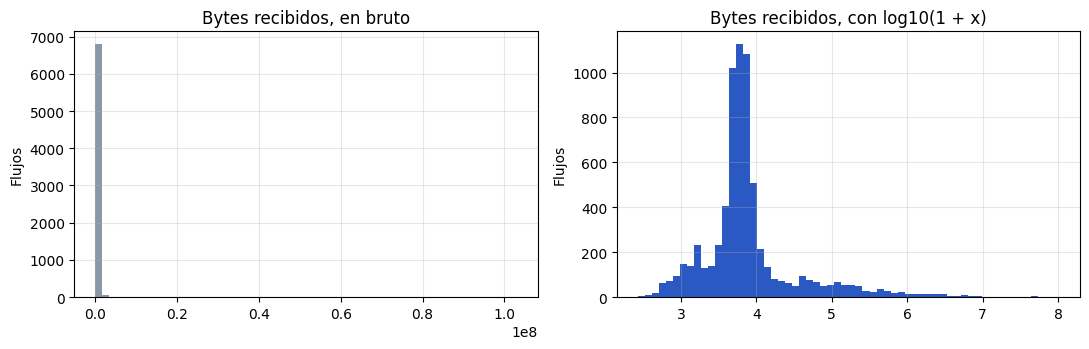

Asimetría en la muestra: 27.2 en bruto · 1.89 transformada


In [8]:
bruto = muestra["BYTES_REV"].astype(float)
transformado = np.log10(1 + bruto)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(bruto, bins=60, color="#8A97A6")
ejes[0].set_title("Bytes recibidos, en bruto")
ejes[1].hist(transformado, bins=60, color="#2B59C3")
ejes[1].set_title("Bytes recibidos, con log10(1 + x)")
for eje in ejes:
    eje.set_ylabel("Flujos")
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Asimetría en la muestra: {bruto.skew():.1f} en bruto · {transformado.skew():.2f} transformada")

Después de la transformación, la distribución deja de estar aplastada contra el cero y el modelo puede distinguir
diferencias entre flujos pequeños y medianos. La función del proyecto aplica esta transformación solo a las seis
variables de la lista `SKEWED`, como se comprueba a continuación.

In [9]:
X = dp.variables_tabulares(muestra)
print("Matriz tabular:", X.shape, "· valores no finitos:", int((~np.isfinite(X)).sum()))
print("Variables con log10(1 + x):", ", ".join(dp.SKEWED))

Matriz tabular: (6900, 60) · valores no finitos: 0
Variables con log10(1 + x): DURATION, BYTES, BYTES_REV, PACKETS, PACKETS_REV, PPI_DURATION


El escalado de las variables, en cambio, no se hace aquí. Debe ajustarse solo con los datos de entrenamiento, dentro
del propio modelo, para no filtrar información de la prueba. Los modelos de árboles, además, no lo necesitan.

## 5. La secuencia de paquetes

Las redes neuronales no usan las 60 variables, sino la secuencia de los primeros 30 paquetes de cada flujo. De cada
paquete se toman tres valores: su tamaño, su dirección (del cliente al servidor o al revés) y el tiempo transcurrido
desde el anterior.

In [10]:
S, mascara = dp.secuencias(muestra)
print("Secuencias:", S.shape, "(flujos, paquetes, valores por paquete)")
print(f"Posiciones de relleno en la muestra: {mascara.mean() * 100:.1f} %")
print(f"En los datos completos, según el EDA: {resumen_eda['secuencia']['posiciones_de_relleno_%']} %")

Secuencias: (6900, 30, 3) (flujos, paquetes, valores por paquete)
Posiciones de relleno en la muestra: 51.3 %
En los datos completos, según el EDA: 51.62 %


Muchos flujos tienen menos de 30 paquetes, y las posiciones vacías se rellenan con ceros. En los datos completos, más
de la mitad de las posiciones son relleno. Por eso la función devuelve también una máscara, que le indica al
Transformer qué posiciones debe ignorar en lugar de tratarlas como paquetes reales. La figura dibuja la firma de un
flujo: cada barra es un paquete, hacia arriba si va del cliente al servidor y hacia abajo si vuelve.

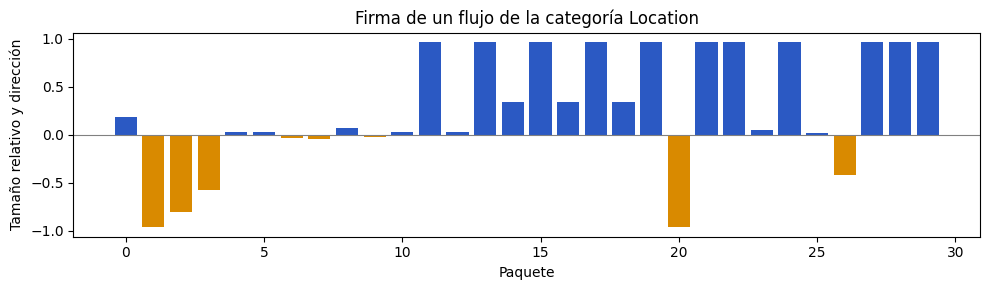

In [11]:
indice = int(np.argmax((~mascara).sum(axis=1) >= 20))
tamano, direccion = S[indice, :, 0], S[indice, :, 1]
reales = ~mascara[indice]

fig, eje = plt.subplots(figsize=(10, 3))
colores = np.where(direccion[reales] > 0, "#2B59C3", "#D98A00")
eje.bar(np.arange(reales.sum()), tamano[reales] * direccion[reales], color=colores)
eje.axhline(0, color="grey", lw=0.8)
eje.set_title(f"Firma de un flujo de la categoría {muestra.CATEGORY.iloc[indice]}")
eje.set_xlabel("Paquete")
eje.set_ylabel("Tamaño relativo y dirección")
plt.tight_layout()
plt.show()

## 6. Etiquetas y desbalance

Las 23 categorías se convierten en números con un orden fijo y alfabético, que se reutiliza en todas las particiones
para que un mismo número signifique siempre la misma categoría. El problema principal de las etiquetas es el
desbalance, que se ve en los datos de entrenamiento completos.

In [12]:
clases = pd.read_csv(RES / "eda" / "clases_por_particion.csv").set_index("CATEGORY")
entrenamiento = clases["entrenamiento"].sort_values(ascending=False)
print(f"Categoría más frecuente: {entrenamiento.index[0]} ({entrenamiento.iloc[0]:,} flujos)".replace(",", " "))
print(f"Categoría menos frecuente: {entrenamiento.index[-1]} ({entrenamiento.iloc[-1]:,} flujos)".replace(",", " "))
print(f"Razón de desbalance: {entrenamiento.iloc[0] / entrenamiento.iloc[-1]:.1f} a 1")

Categoría más frecuente: Advertising (85 927 flujos)
Categoría menos frecuente: Virtual assistant (593 flujos)
Razón de desbalance: 144.9 a 1


Entre la categoría más frecuente y la menos frecuente hay una razón de casi 145 a 1. Sin corrección, un modelo
aprendería a ignorar los servicios pequeños. La corrección que usa el proyecto son los pesos por clase: cada flujo
pesa en el entrenamiento de forma inversamente proporcional a la frecuencia de su categoría.

In [13]:
pesos = pd.Series(leer_json(RES / "eda" / "pesos_por_clase.json"), name="Peso").sort_values()
pd.concat([pesos.head(3), pesos.tail(3)]).to_frame()

,Peso
Advertising,0.4049
Social,0.4313
Media,0.5123
Internet banking,8.9155
Remote desktop,41.6126
Virtual assistant,58.6647


Un flujo de asistente virtual pesa muchas veces más que uno de publicidad. Así, equivocarse en una categoría pequeña
cuesta tanto como equivocarse en una grande, que es justo lo que mide el F1 macro.

## 7. Partición en el tiempo y secuencias repetidas

Los datos no se dividen al azar, sino por meses, porque un clasificador de tráfico se entrena con el pasado y se usa
en el futuro. Septiembre se usa para entrenar (80 %) y validar (20 %), octubre para la prueba final, y noviembre y
diciembre para medir la deriva.

In [14]:
cfg = yaml.safe_load((RAIZ / "configs" / "experiment.yaml").read_text(encoding="utf-8"))
print("Meses por uso:", cfg["datos"]["meses"])
repetidos = resumen_eda["repetidos"]
print(f"Flujos de prueba cuya secuencia ya apareció en entrenamiento: {repetidos['prueba_con_secuencia_vista_en_entrenamiento_%']} %")
print("Por longitud de la secuencia (%):", {k: v for k, v in repetidos["por_longitud_%"].items() if v == v})

Meses por uso: {'entrenamiento': '2022-09', 'prueba': '2022-10', 'deriva': ['2022-11', '2022-12']}
Flujos de prueba cuya secuencia ya apareció en entrenamiento: 30.33 %
Por longitud de la secuencia (%): {'(2, 5]': 81.76, '(5, 10]': 48.52, '(10, 20]': 15.76, '(20, 30]': 2.31}


Un 30,3 % de los flujos de prueba repite exactamente una secuencia de paquetes que ya apareció en entrenamiento, sobre
todo los flujos cortos. Esto tiene dos consecuencias en el resto del proyecto: el desempeño se reporta también sin
esas secuencias repetidas, y en la validación cruzada de la semana 5 los pliegues se agruparon por secuencia para que
una misma secuencia nunca quedara a la vez en entrenamiento y en validación.

## Conclusiones

1. Cada flujo se representa de dos formas: 60 variables tabulares para los modelos de árboles y una secuencia de 30
   paquetes con su máscara para las redes neuronales.
2. Se excluyen las variables que identifican personas o servicios y la que filtraba la respuesta, el ASN de destino.
3. Las seis variables más asimétricas se comprimen con log10(1 + x); el escalado queda dentro de cada modelo.
4. El desbalance de 145 a 1 se compensa con pesos por clase.
5. La partición es temporal, y las secuencias repetidas obligan a evaluar con cuidado la generalización.